# Simple Linear Regression Lab
## Auto MPG Dataset

Name: Vaibhav Yadav
Roll Number: 2401CS70
Date: 11 August 2026

In [3]:
import pandas as pd
df = pd.read_csv('/content/auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


Number of observations and attributes

In [4]:
df.shape

(398, 9)

Data types


In [5]:
df.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,int64
car name,object


Missing values

In [6]:
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
origin,0
car name,0


Duplicate observations

In [7]:
df.duplicated().sum()

np.int64(0)

Descriptive statistics for the two required variables

In [8]:
df[['weight', 'mpg']].describe()

,weight,mpg
count,398.000000,398.000000
mean,2970.424623,23.514573
std,846.841774,7.815984
min,1613.000000,9.000000
25%,2223.750000,17.500000
50%,2803.500000,23.000000
75%,3608.000000,29.000000
max,5140.000000,46.600000


In [10]:
import matplotlib.pyplot as plt

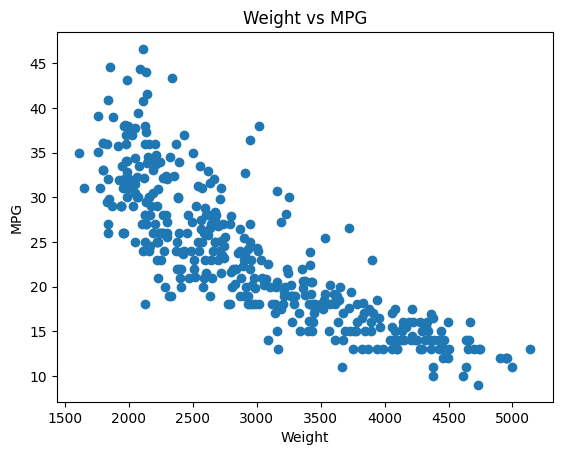

In [11]:
plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('Weight vs MPG')
plt.show()

Q1.
ANS - No. Weight has a strong relationship with MPG, but other factors also affect MPG. So weight alone cannot predict every vehicle accurately.

Q2.ANS - It shows that weight is not the only factor affecting MPG. Other vehicle features also influence fuel efficiency.

Q3.ANS - No. Correlation shows a relationship, but it does not prove that one variable directly causes the other.

**TASK** **2** : Data Preprocessing and Train-Test Split

In [16]:
X = df[['weight']]
y = df['mpg']

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 318
Testing samples: 80


Q1.ANS - Because the test data should be used only to check the model. Using it during training can make the results look better than they really are.

Q2.ANS - The model may see the same or very similar data during training and testing. So the test result may look better, even though the model has not really learned to handle new data.

Q3.ANS - Different splits contain different training and testing samples. Since the model is fitted on different data, its predictions and R² can also change.

## Task 3: Simple Linear Regression Model

In [20]:
def predict(x, slope, intercept):
    return slope * x + intercept

In [21]:
x_train = X_train['weight'].values
y_train = y_train.values

slope = ((x_train - x_train.mean()) * (y_train - y_train.mean())).sum() / ((x_train - x_train.mean()) ** 2).sum()
intercept = y_train.mean() - slope * x_train.mean()

print("Slope:", slope)
print("Intercept:", intercept)

Slope: -0.007805242351594881
Intercept: 46.78206336645047


In [22]:
y_pred = predict(X_test['weight'].values, slope, intercept)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[32.77165335 26.29330219 26.22305501 16.0294085  13.71125152 30.39105443
 24.42004403  9.82424083 15.09277942 24.34199161]


In [23]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R²:", r2)

MSE: 14.894861064636192
R²: 0.722971057303075


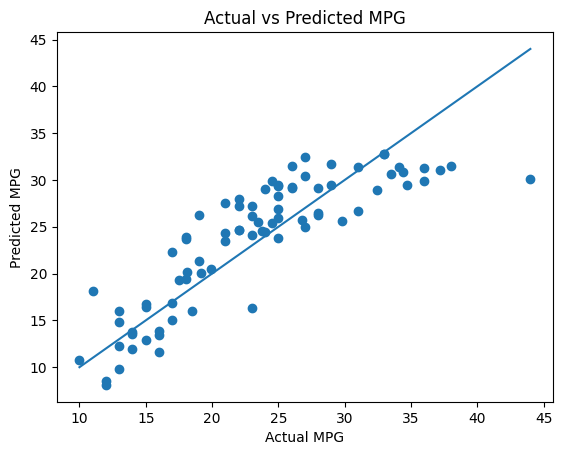

In [24]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()])
plt.show()

Q1.ANS - For every 1-unit increase in vehicle weight, the predicted MPG decreases by 0.007.

Q2.ANS - Not really, because a vehicle cannot have zero weight. It is mainly the mathematical starting point of the regression line.

Q3.ANS - It means weight has very little linear relationship with MPG and may not be a useful predictor by itself.


**Task 4: Implement the Prediction Error and Loss Function**

In [25]:
def squared_error_loss(y_true, y_pred):

    return (y_true - y_pred) ** 2

In [27]:
def squared_error_loss(y_true, y_pred):
    return (y_true - y_pred) ** 2

for i in range(5):
    actual = y_test.values[i]
    predicted = y_pred[i]
    error = actual - predicted
    loss = squared_error_loss(actual, predicted)

    print("Weight:", X_test['weight'].values[i])
    print("Actual MPG:", actual)
    print("Predicted MPG:", predicted)
    print("Error:", error)
    print("Loss:", loss)
    print("--------------------")

Weight: 1795
Actual MPG: 33.0
Predicted MPG: 32.77165334533766
Error: 0.22834665466233872
Loss: 0.05214219469548138
--------------------
Weight: 2625
Actual MPG: 28.0
Predicted MPG: 26.29330219351391
Error: 1.7066978064860905
Loss: 2.912817402664433
--------------------
Weight: 2634
Actual MPG: 19.0
Predicted MPG: 26.223055012349555
Error: -7.223055012349555
Loss: 52.17252371142803
--------------------
Weight: 3940
Actual MPG: 13.0
Predicted MPG: 16.02940850116664
Error: -3.029408501166639
Loss: 9.177315866940702
--------------------
Weight: 4237
Actual MPG: 14.0
Predicted MPG: 13.711251522742963
Error: 0.28874847725703745
Loss: 0.08337568311825787
--------------------


Q1.ANS - Because squaring removes the negative sign. Both +5 and −5 give a loss of 25.

Q2.ANS - Because squaring makes large errors much bigger. So one very large error can have a much higher loss than several small errors.

Q3.ANS - Positive and negative errors can cancel each other out. This can make the total error look small even when the predictions are not accurate.

**Task 5: Implement the Cost Function**

In [30]:
def compute_cost(y_true, y_pred):
    n = len(y_true)
    total = 0

    for i in range(n):
        error = y_true[i] - y_pred[i]
        total += error ** 2

    return total / n

In [33]:
y_train_pred = predict(X_train['weight'].values, slope, intercept)

train_cost = compute_cost(y_train, y_train_pred)
test_cost = compute_cost(y_test.values, y_pred)

print("Training Data MSE Cost:", train_cost)
print("Testing Data MSE Cost:", test_cost)

Training Data MSE Cost: 19.781923945400276
Testing Data MSE Cost: 14.8948610646362


Q1.ANS - No. One very bad prediction can be hidden by the average MSE, so we should also check other metrics and individual errors.

Q2.ANS - MSE is more sensitive to outliers because it squares the errors. Large errors therefore have a much bigger effect.

Q3.ANS - The MSE becomes one-fourth (25%) of the original value because the errors are squared.

**Task 6: Calculate the Slope and Intercept from Scratch**

In [37]:
def calculate_intercept(x, y, slope):
    x_mean = x.mean()
    y_mean = y.mean()

    intercept = y_mean - slope * x_mean

    return intercept

In [38]:
def calculate_slope(x, y):
    x_mean = x.mean()
    y_mean = y.mean()

    numerator = ((x - x_mean) * (y - y_mean)).sum()
    denominator = ((x - x_mean) ** 2).sum()

    slope = numerator / denominator

    return slope

In [39]:
x_train = X_train['weight'].values

slope_manual = calculate_slope(x_train, y_train)
intercept_manual = calculate_intercept(x_train, y_train, slope_manual)

print("Mean Vehicle Weight:", x_train.mean())
print("Mean MPG:", y_train.mean())
print("Slope:", slope_manual)
print("Intercept:", intercept_manual)

Mean Vehicle Weight: 2969.01572327044
Mean MPG: 23.60817610062893
Slope: -0.007805242351594881
Intercept: 46.78206336645047


Q1.ANS - Deviations from the mean show how x and y move together around their averages.

Q2.ANS - If all weights are the same, the denominator becomes zero, so the slope cannot be calculated.

Q3.ANS - The relationship stays the same, but the numerical slope changes because the unit of weight changes from pounds to kilograms.

**Task 7: Generate Predictions Using the Manual Model**

In [40]:

y_train_pred_manual = predict(X_train['weight'].values, slope_manual, intercept_manual)
y_test_pred_manual = predict(X_test['weight'].values, slope_manual, intercept_manual)

In [41]:
for i in range(10):
    weight = X_test['weight'].values[i]
    actual = y_test.values[i]
    predicted = y_test_pred_manual[i]
    error = actual - predicted

    print("Weight:", weight,
          "| Actual MPG:", actual,
          "| Predicted MPG:", predicted,
          "| Error:", error)

Weight: 1795 | Actual MPG: 33.0 | Predicted MPG: 32.77165334533766 | Error: 0.22834665466233872
Weight: 2625 | Actual MPG: 28.0 | Predicted MPG: 26.29330219351391 | Error: 1.7066978064860905
Weight: 2634 | Actual MPG: 19.0 | Predicted MPG: 26.223055012349555 | Error: -7.223055012349555
Weight: 3940 | Actual MPG: 13.0 | Predicted MPG: 16.02940850116664 | Error: -3.029408501166639
Weight: 4237 | Actual MPG: 14.0 | Predicted MPG: 13.711251522742963 | Error: 0.28874847725703745
Weight: 2100 | Actual MPG: 27.0 | Predicted MPG: 30.39105442810122 | Error: -3.3910544281012207
Weight: 2865 | Actual MPG: 24.0 | Predicted MPG: 24.420044029131137 | Error: -0.42004402913113736
Weight: 4735 | Actual MPG: 13.0 | Predicted MPG: 9.824240831648709 | Error: 3.1757591683512914
Weight: 4060 | Actual MPG: 17.0 | Predicted MPG: 15.092779418975255 | Error: 1.9072205810247453
Weight: 2875 | Actual MPG: 21.0 | Predicted MPG: 24.34199160561519 | Error: -3.3419916056151884


Q1.ans - Because the model uses only weight. The same weight gives the same predicted MPG, even if the actual MPG is different.

Q2.ANS - Yes. The model can predict values that were not present in the training data because it calculates a continuous value from the regression equation.

Q3.ANS - It is riskier because the model has not seen data in that range during training, so the prediction is an extrapolation and may be less reliable.

**Task 8: Visualize the Fitted Regression Line**

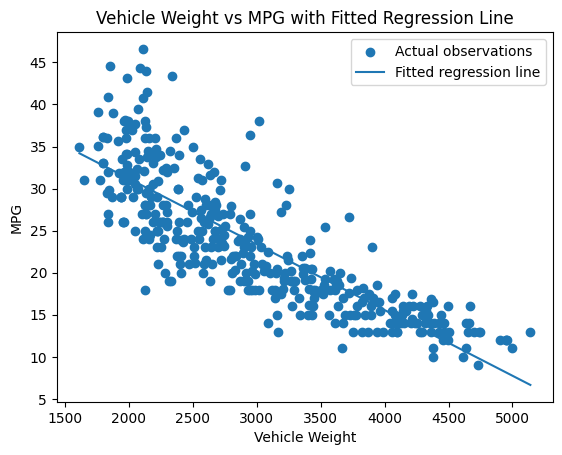

In [42]:

x_line = X['weight'].sort_values()
y_line = predict(x_line.values, slope_manual, intercept_manual)


plt.scatter(df['weight'], df['mpg'], label='Actual observations')


plt.plot(x_line, y_line, label='Fitted regression line')

plt.xlabel('Vehicle Weight')
plt.ylabel('MPG')
plt.title('Vehicle Weight vs MPG with Fitted Regression Line')
plt.legend()
plt.show()

Q1.ANS - Because the line minimizes the overall error. It cannot pass through every observation when the data points are scattered.

Q2.ANS - It represents the prediction error (residual) — the difference between the actual MPG and predicted MPG.

Q3.ANS - I would trust the dataset with points tightly clustered around the line because its predictions are likely to be more consistent and have smaller errors.

**Task 9: Implement Evaluation Metrics from Scratch**

In [43]:
import math

def calculate_mae(y_true, y_pred):
    total = 0
    n = len(y_true)

    for i in range(n):
        total += abs(y_true[i] - y_pred[i])

    return total / n


def calculate_mse(y_true, y_pred):
    total = 0
    n = len(y_true)

    for i in range(n):
        total += (y_true[i] - y_pred[i]) ** 2

    return total / n


def calculate_rmse(y_true, y_pred):
    mse = calculate_mse(y_true, y_pred)
    return math.sqrt(mse)


def calculate_r2(y_true, y_pred):
    y_mean = y_true.mean()

    ss_res = 0
    ss_tot = 0

    for i in range(len(y_true)):
        ss_res += (y_true[i] - y_pred[i]) ** 2
        ss_tot += (y_true[i] - y_mean) ** 2

    return 1 - (ss_res / ss_tot)

In [44]:
mae = calculate_mae(y_test.values, y_test_pred_manual)
mse = calculate_mse(y_test.values, y_test_pred_manual)
rmse = calculate_rmse(y_test.values, y_test_pred_manual)
r2 = calculate_r2(y_test.values, y_test_pred_manual)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 3.117786199206457
MSE: 14.8948610646362
RMSE: 3.859386099451077
R²: 0.7229710573030748


Q1.ANS - Not necessarily. A high R² can still happen with a few very large errors, so we should also check MAE, MSE, and RMSE.

Q2.ANS - RMSE gives more importance to large errors because it squares them. MAE treats all errors more evenly.

Q3.ANS - It means the model performs worse than simply predicting the mean MPG for every vehicle.

**Task 10: Implement Simple Linear Regression Using Scikit-learn**

In [45]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_library = model.predict(X_test)

In [46]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: -0.00780524235159488
Intercept: 46.78206336645047


In [47]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import math

mae_library = mean_absolute_error(y_test, y_pred_library)
mse_library = mean_squared_error(y_test, y_pred_library)
rmse_library = math.sqrt(mse_library)
r2_library = r2_score(y_test, y_pred_library)

print("MAE:", mae_library)
print("MSE:", mse_library)
print("RMSE:", rmse_library)
print("R²:", r2_library)

MAE: 3.1177861992064573
MSE: 14.894861064636194
RMSE: 3.8593860994510765
R²: 0.722971057303075


Q1.ANS - I would first check the slope calculation, intercept calculation, and whether the same training data was used.

Q2.ANS - Because both methods use the same data and the same linear regression formula, their results should be almost identical.

Q3.ANS - Implementing it manually shows that I understand how Linear Regression works instead of only knowing how to call a library function.

**Task 11: Compare Manual and Scikit-learn Implementations**

In [48]:
comparison = {
    "Parameter / Metric": [
        "Slope",
        "Intercept",
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],
    "From Scratch": [
        slope_manual,
        intercept_manual,
        mae,
        mse,
        rmse,
        r2
    ],
    "Scikit-learn": [
        model.coef_[0],
        model.intercept_,
        mae_library,
        mse_library,
        rmse_library,
        r2_library
    ]
}

comparison_df = pd.DataFrame(comparison)

comparison_df["Difference"] = (
    comparison_df["From Scratch"] - comparison_df["Scikit-learn"]
).abs()

comparison_df

,Parameter / Metric,From Scratch,Scikit-learn,Difference
0,Slope,-0.007805,-0.007805,8.673617e-19
1,Intercept,46.782063,46.782063,0.000000e+00
2,MAE,3.117786,3.117786,4.440892e-16
3,MSE,14.894861,14.894861,5.329071e-15
4,RMSE,3.859386,3.859386,4.440892e-16
5,R²,0.722971,0.722971,2.220446e-16


The manual and Scikit-learn results are almost identical. Small numerical differences, if any, are due to floating-point calculations.

Q1.ANS - The error is probably in the prediction step, such as using the wrong X values or a different slope/intercept.

Q2.ANS - No. R² alone is not enough because different predictions can sometimes produce the same or very similar R².

Q3.ANS- Matching the predictions provides stronger evidence because the coefficients are used directly to generate the predictions. Matching coefficients and evaluation metrics together gives the strongest overall confirmation.

**Task 12: Residual Analysis**

In [49]:
residuals = y_test.values - y_test_pred_manual

mean_residual = residuals.mean()

print("Mean Residual:", mean_residual)

Mean Residual: -0.410966997045316


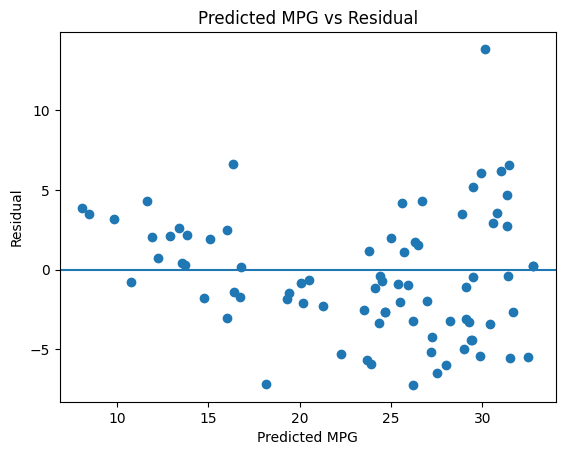

In [50]:
plt.scatter(y_test_pred_manual, residuals)
plt.axhline(0)
plt.xlabel("Predicted MPG")
plt.ylabel("Residual")
plt.title("Predicted MPG vs Residual")
plt.show()

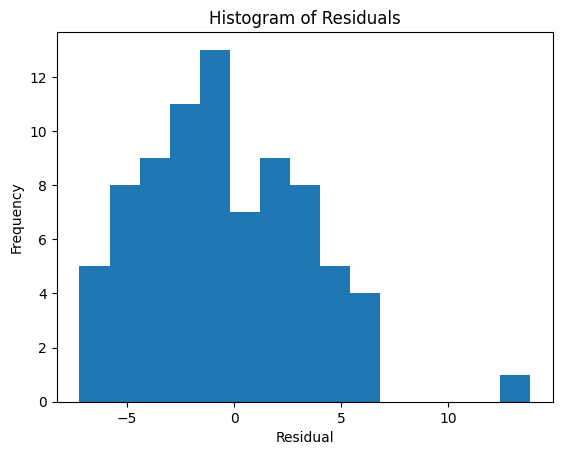

In [51]:
plt.hist(residuals, bins=15)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

The residuals appear reasonably scattered around zero, although there may be some variation. The mean residual is close to zero.

Q1.ANS - A curved pattern suggests that the relationship between weight and MPG may not be fully linear.

Q2.ANS - It indicates that the regression line is systematically overpredicting or underpredicting in different weight ranges.

Q3.ANS - Random residuals around zero suggest that the model has captured the main linear relationship and there is no obvious remaining pattern.

**Task 13: Final Analysis and Critical Thinking**

Weight and MPG have a clear negative relationship. As vehicle weight increases, MPG generally decreases. The model gives a reasonable prediction, but weight alone cannot explain all the variation in MPG. The residuals should be checked for patterns, and the model has limitations because it uses only one vehicle attribute. Other factors may also affect MPG.

Q1.ANS - Weight explains a large part of MPG variation, but other vehicle factors can also affect MPG. Therefore, some vehicles can still have large prediction errors.

Q2.ANS - I would choose horsepower, because engine power can affect fuel consumption and may provide additional information beyond vehicle weight.

Q3.ANS - No. A high R² alone is not enough. A strong pattern in the residuals suggests that the model is missing some relationship in the data, so the model may not be a good representation of the data.